In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Distribuição Gamma

## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

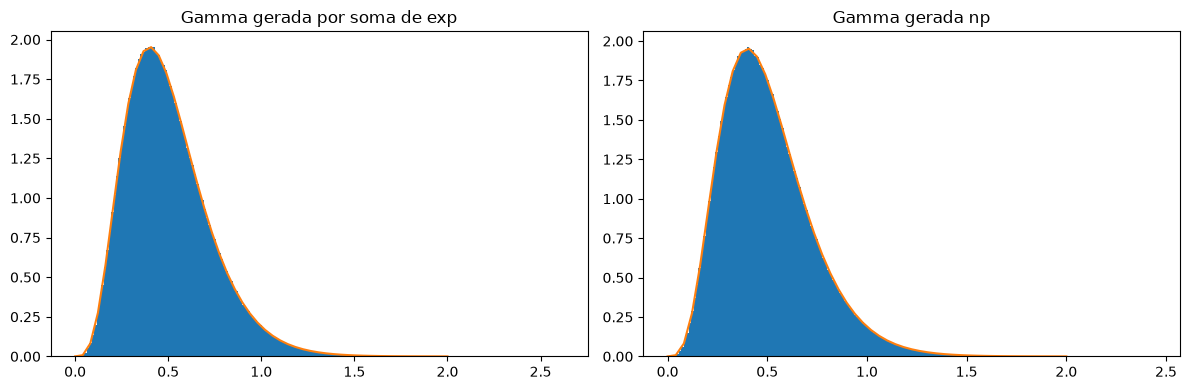

In [2]:
M = 5_000_000
k = 5
lamb = 10
unis = np.random.uniform(size=(M,k))
exps = -np.log(unis)/lamb
gammas = np.sum(exps, axis=1)
gammas_np = np.random.gamma(k, 1/lamb, size=M)
fig, ax = plt.subplots(1,2, figsize=(12,4))
x = np.linspace(0,2)
def densidade_gamma(x, a, b):
    return b**a/ math.gamma(a) *x**(a-1)*np.exp(-b*x)
y = densidade_gamma(x, k, lamb)
ax[0].hist(gammas, bins=200, density=True)
ax[0].plot(x,y)
ax[0].set_title('Gamma gerada por soma de exp')
ax[1].set_title('Gamma gerada np')
ax[1].hist(gammas_np, bins=200, density=True)
ax[1].plot(x,y)
fig.tight_layout()
plt.show()


## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [3]:
mi = 3
a = 2.5
lamb = 10 # mi < lamb
def densidade_exp(x, mi):
    return mi * np.exp(-mi*x)
x_est = (a-1)/(lamb-mi)

c = densidade_gamma(x_est, a, lamb) / densidade_exp(x_est, mi)

In [4]:
M = 100_000
amostras_gamma = []
for _ in range(M):
    u = np.random.uniform()
    exp = -np.log(np.random.uniform())/mi
    while u * c * densidade_exp(exp, mi) > densidade_gamma(exp, a, lamb):
        u = np.random.uniform()
        exp = -np.log(np.random.uniform())/mi
    amostras_gamma.append(exp)

In [8]:
x = np.linspace(0,3, num = 100)
fx = densidade_gamma(x, a, lamb)

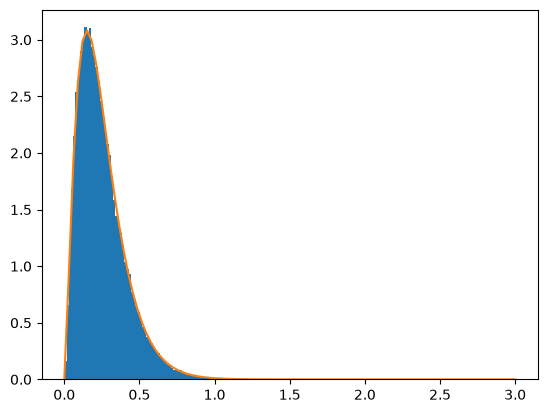

In [9]:
plt.hist(amostras_gamma, density=True, bins= 100)
plt.plot(x,fx)

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [51]:
alfa = 1.5
lamb = 3
mi = 1
x_est = (alfa-1)/(lamb-mi)
c = densidade_gamma(x_est, a, lamb) / densidade_exp(x_est, mi)

amostras_gamma_1ponto5 = []
for _ in range(M):
    u = np.random.uniform()
    exp = -np.log(np.random.uniform())/mi
    while u * c * densidade_exp(exp, mi) > densidade_gamma(exp, alfa, lamb):
        u = np.random.uniform()
        exp = -np.log(np.random.uniform())/mi
    amostras_gamma_1ponto5.append(exp)

In [52]:
G = np.array(amostras_gamma_1ponto5)
U = np.random.uniform(size= M)
X = G * U **(1/(alfa-1))

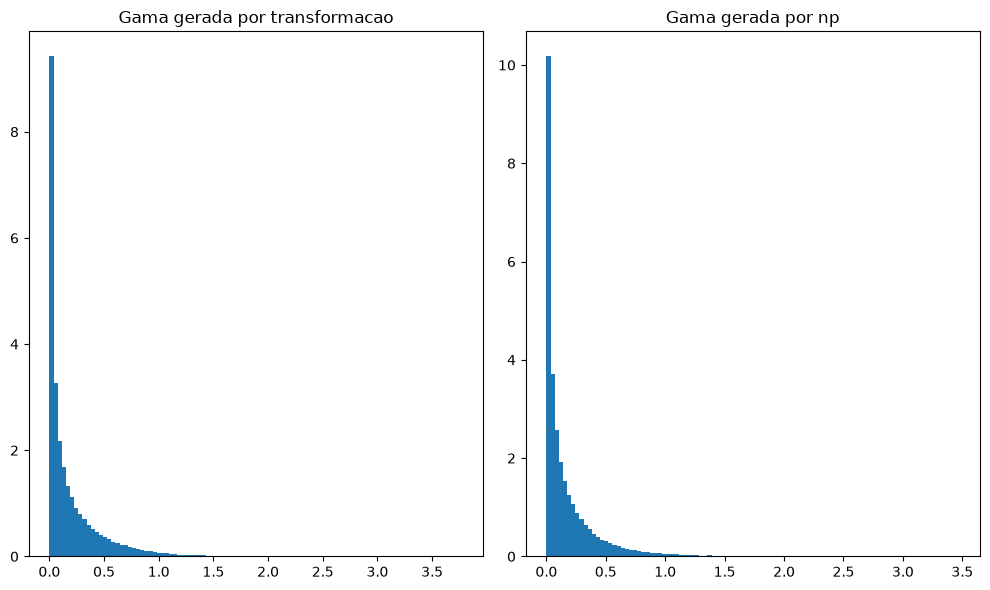

In [54]:
fig, ax = plt.subplots(1,2, figsize= (10,6))

ax[0].hist(X, density= True, bins = 100)
ax[0].set_title("Gama gerada por transformacao")
gamma_np = np.random.gamma(alfa - 1, 1/lamb, size=M)
ax[1].hist(gamma_np, density=True, bins = 100)
ax[1].set_title("Gama gerada por np")
plt.tight_layout()
plt.show()

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.